# Bank customer retention: from risk scores to a measurable pilot

A bank loses money in two directions: paying to contact customers who were never going to leave, and letting profitable customers go unnoticed. This report measures how far a retrospective risk score helps balance the two, on a supplied file of 10,000 customer records in which 20.4% carry a departure label. A random forest with sigmoid calibration was selected on validation average precision and evaluated once on a held-out test set, reaching ROC-AUC 0.857 (95% interval 0.835–0.877). At an illustrative capacity of 400 contacts among 2,000 test customers, it targets 248 of 407 departure labels — 62% precision, 3.05 lift — against 169 for a frozen business rule and 85 for a fixed random draw. Under the frozen reference economics that is US\$20,800 of simulated net gain; with no retention effect the same campaign loses US\$4,000. The value therefore depends entirely on an effect nobody has measured, which is why the recommendation is a randomized pilot rather than a campaign.

This report brings together the four analytical notebooks and reads only their frozen aggregate outputs. It introduces no model, no test evaluation and no targeting choice.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'brief.md').exists() else Path.cwd().parent
assert (ROOT / 'brief.md').exists()
sys.path.insert(0, str(ROOT / 'src'))
from presentation import display, en, segment_rate_figure
OUT = ROOT / 'data/results'
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
contract = json.loads((ROOT / 'data/processed/contract.json').read_text())
protocol = json.loads((OUT / 'frozen_protocol.json').read_text())
result = json.loads((OUT / 'test_evaluation.json').read_text())
eda = json.loads((OUT / 'eda_summary.json').read_text())
segments = pd.read_csv(OUT / 'segments_train.csv')
validation = pd.read_csv(OUT / 'validation_metrics.csv', index_col='modele')
scenarios = pd.read_csv(OUT / 'business_scenarios.csv')
assert result['freeze_sha256'] == sha(OUT / 'frozen_protocol.json')
assert contract['raw_sha256'] == protocol['raw_sha256']
assert contract['split_sha256'] == eda['source_split_sha256'] == protocol['split_sha256']
assert result['selected_model'] == protocol['selected_model']
strategies = pd.DataFrame(result['strategies'])
economics = protocol['economics']
reference = scenarios[(scenarios.q == economics['q']) & (scenarios.marge_eur == economics['margin_eur']) & (scenarios.cout_par_contact_eur == economics['cost_eur'])]
pd.testing.assert_series_equal(reference.set_index('strategie').gain_net_scenario_eur.sort_index(), strategies.set_index('strategie').gain_net_scenario_eur.sort_index(), check_names=False, check_dtype=False)
plt.rcParams.update({'figure.figsize':(9,5),'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'text.parse_math':False})

## 1. The business problem

A retention team can lose money in two directions. Contacting a customer who was never going to leave spends the offer for nothing, and every departure that goes unnoticed takes its margin along. The second loss is the larger one: under the assumptions used throughout this report, one prevented departure preserves US\$500 of net margin over twelve months, while a contact costs US\$10 — US\$2 of contact plus US\$8 of offer, paid for everyone contacted, whether they intended to leave or not. One prevented departure therefore pays for the fifty contacts that produced it. These figures are illustrative conventions fixed for the study, not estimates from a campaign.

That asymmetry changes the question. The objective is not to rank customers by risk, but to decide who is worth contacting under explicit margin, cost and effect assumptions. Section 5 applies the frozen capacity policy to those assumptions; no profitability threshold on the score was derived, because none was frozen before the test.

The population defines what can be claimed. Every observation is a customer already present in the supplied file, one record each, with no campaign history: nobody in this dataset was contacted, so no response to an offer is observed anywhere in the data. The analysis evaluates **targeting within a retrospective customer base**. Claiming that a contact prevents a departure would require an intervention and a control group, which section 7 proposes.

The file also carries no dates. Snapshot date, decision date, label horizon and censoring rule are unknown, and whether each predictor was available before the departure cannot be checked. What follows is a retrospective ranking, not a prospective forecast.

## 2. The data

The study uses the supplied customer file `Churn_Modelling.csv`: **10,000 rows and 14 columns**, one observed record per customer. Notebook 01 found no missing values, no exact duplicates, no repeated customer identifier and no failure in its stated plausibility checks. Every row was kept and no rare profile was removed automatically. The customers are located in France (3,010 of the 6,000 training records), Germany (1,481) and Spain (1,509), with no established representativeness of any real portfolio.

The outcome is the binary `Exited` column. The [Microsoft Learn example](https://learn.microsoft.com/en-us/fabric/data-science/customer-churn) describes a dataset of matching structure as account closure, and the study **infers** the educational convention **1 = departure, 0 = no observed departure** from that match, from sample observations and from the class counts. *The label is a documented convention, not a certified operational churn definition: no horizon, no decision date and no censoring rule accompany it, so none of the proportions in this report is an annual churn rate, and the full provenance and licence of the supplied file remain uncertified.* In total, 1,222 of the 6,000 training customers — **20.4%** — carry a departure label.

Nine predictors are used: credit score, age, tenure, balance, estimated salary, country, number of products, card ownership and membership activity. Row number, customer identifier and surname are excluded as identifiers; gender is excluded by design, which does not rule out indirect bias through correlated features. A zero balance stays a valid observation and a balance is never treated as a margin, since the currency of the file's amounts is unknown.

The split was frozen before any predictor–target relationship was explored: **6,000 training / 2,000 validation / 2,000 test**, stratified, seed 42. With unique customers and no dates this is an exchangeability assumption, not a temporal validation. Every learned step — imputation, scaling, encoding, calibration — is fitted on training data inside pipelines, and the test results read here remain cached and unchanged.

## 3. What the customer base looks like

One customer in five carries a departure label, so the value of a score will come from separating a sizeable minority, not from reshaping the whole base. Notebook 02 examined the training set only. The proportions below are unadjusted: each mixes the factor with everything correlated with it, and none is adjusted for multiple comparisons.

**Number of products** has the steepest gradient, from 7.9% for two products (n = 2,777) to 82.0% for three (n = 172), with 27.3% for a single product (n = 3,012). **Age** comes next: 8.1% among customers aged 18–34 (n = 2,209) against 48.5% among those aged 45–54 (n = 853). **Membership activity** separates 26.4% for inactive customers (n = 2,901) from 14.7% for active ones (n = 3,099). **Country** places Germany at 32.5% (n = 1,481) against France at 16.1% and Spain at 16.9%.

Two patterns reverse direction and must not be read as effects. The age proportion falls back to 37.5% above 55, and customers with a zero balance carry fewer departure labels (14.1%) than those with a positive balance (24.0%), a counterintuitive ordering. The frozen aggregates hold one-way segment proportions only, with no two-way or adjusted decomposition, so neither reversal can be attributed here to composition rather than to a stable pattern.

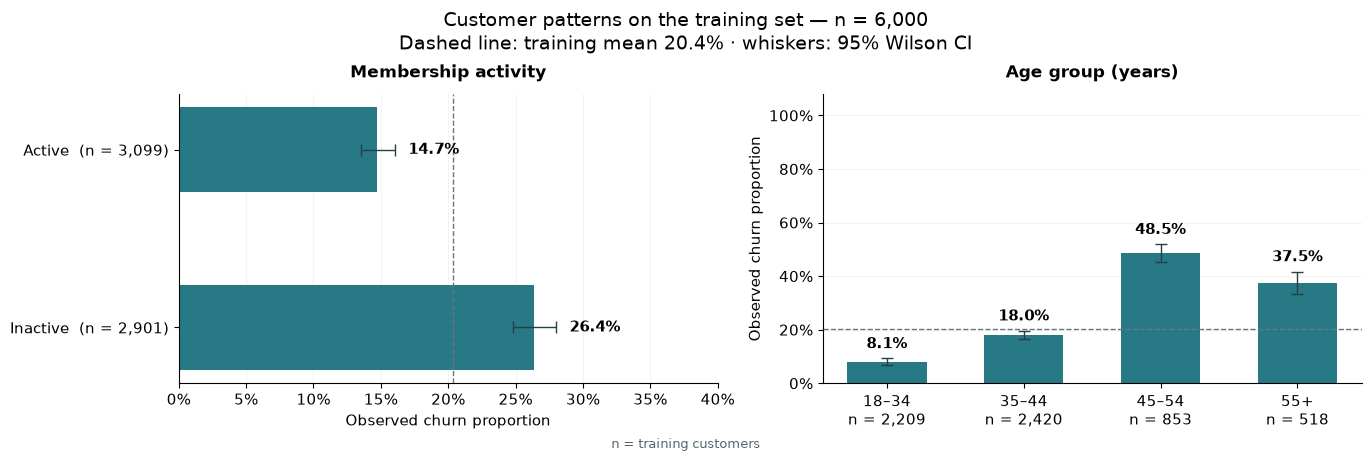

In [2]:
segment_rate_figure(segments, ['IsActiveMember','AgeBand'], eda['prevalence_train'], title='Customer patterns on the training set — n = 6,000')
plt.show()

The figure keeps the existing 95% Wilson intervals and group sizes, with age bands in their natural order and the dashed line at the 20.4% training mean. The intervals assume independent customers and cover sampling only; they capture neither selection bias nor drift.

Two groups are too thin to interpret and are left uninterpreted. The four-product group holds 39 training customers, all carrying a departure label, and the three-product group holds 172. A proportion of 100% among 39 customers is not evidence of future certainty.

The modelling implication was to compare a linear classifier against a tree model able to represent these non-monotonic patterns, rather than to turn a marginal segment proportion into a retention rule.

## 4. The model, in plain language

Notebook 03 built three candidates on the frozen training split: a prevalence-only naive baseline, a logistic regression and a random forest, each inside a pipeline fitting median and mode imputation, numerical scaling and one-hot encoding on training folds only. Product count was encoded as a category rather than a number, so the non-monotonic pattern of section 3 can be represented without being assumed.

The selection rule was fixed before the test set was touched: the model family is chosen on validation average precision with the Brier score as tie-breaker, and sigmoid calibration — fitted on five-fold out-of-fold training predictions, with preprocessing refitted inside every fold — is kept only if it improves validation Brier and loses no more than 0.01 of average precision. The random forest won the family comparison on validation (average precision 0.707, against 0.634 for the logistic regression and 0.204 for the baseline), and calibration improved validation Brier from 0.1010 to 0.0996 at unchanged average precision, so the calibrated forest was retained. Model settings, calibration, the 20% capacity quota, tie-breaking, the targeting rules and the economic assumptions were all frozen before the single test evaluation.

In [3]:
test_metrics = pd.DataFrame(result['metrics']).T
comparison = pd.DataFrame({
 'Model':[en(name) for name in validation.index],
 'Validation AP':validation.average_precision.to_numpy(),
 'Validation Brier':validation.brier.to_numpy(),
 'Test ROC-AUC':test_metrics.loc[validation.index,'roc_auc'].to_numpy(),
 'Test AP':test_metrics.loc[validation.index,'average_precision'].to_numpy(),
 'Test Brier':test_metrics.loc[validation.index,'brier'].to_numpy(),
}).set_index('Model')
display(comparison.style.format('{:.3f}'))

,Validation AP,Validation Brier,Test ROC-AUC,Test AP,Test Brier
Model,,,,,
Naive baseline,0.204,0.162,0.500,0.203,0.162
Logistic regression,0.634,0.113,0.833,0.627,0.115
Random forest,0.707,0.101,0.857,0.685,0.105
Random forest (sigmoid),0.707,0.100,0.857,0.685,0.105


**Selected on validation: the random forest with sigmoid calibration.** On the 2,000 test customers it reaches ROC-AUC **0.857** (95% bootstrap interval 0.835–0.877), average precision **0.685** (0.634–0.727) and a Brier score of **0.105** (0.096–0.114). Test prevalence is 20.35%, which is the average precision a constant baseline obtains. Higher ROC-AUC and average precision mean better ranking; a lower Brier score means smaller probability error. The table reports the frozen candidates on a single evaluation; it is not a new selection.

Calibration holds at the aggregate level: mean predicted probability is 20.6% against 20.35% observed. Its benefit on test is marginal — Brier 0.10526 against 0.10534 for the uncalibrated forest — so calibration deserves credit for the validation improvement that motivated it, not for a material test gain, and this is aggregate agreement rather than proven calibration in every score band. The rejected challenger is published too: the logistic regression reaches ROC-AUC 0.833 and targets 232 departure labels at the same capacity, sixteen fewer than the forest.

The 1,000-resample intervals are conditional on the frozen model and the test sample; they omit training and selection uncertainty. The check this study cannot report is the one that matters most. With no dates in the file there is no out-of-time validation on a later cohort, and feature chronology is unverified, so the measured performance may overstate what a prospective deployment would obtain.

## 5. From probability to decision

A probability becomes a policy only once it is combined with capacity and economics. This study froze a capacity rule rather than a profitability threshold: contact the highest-scored 20% of customers, ties broken pseudo-randomly with seed 42, independently of the target. On validation that quota corresponds to a descriptive score cutoff of 0.311 — a consequence of the quota, not a break-even point. No economically derived threshold was frozen before the test, so none is presented as one here, and the quota is illustrative capacity rather than an optimized budget.

Three policies were frozen at the same 400-contact capacity on the same 2,000 test customers, with **no contact** as the incremental reference at zero cost and zero gain: a random draw fixed once with seed 42; a business rule ranking `2 × inactive + 1 × age ≥ 45 years`; and predictive targeting on the selected score. Departure labels targeted below are retrospective labels a policy would reach, **not departures prevented**.

,Contacts,Departure labels targeted,Precision,Recall
Strategy,,,,
No contact,0,0,—,0.0%
Random,400,85,21.2%,20.9%
Business rule,400,169,42.2%,41.5%
Predictive,400,248,62.0%,60.9%


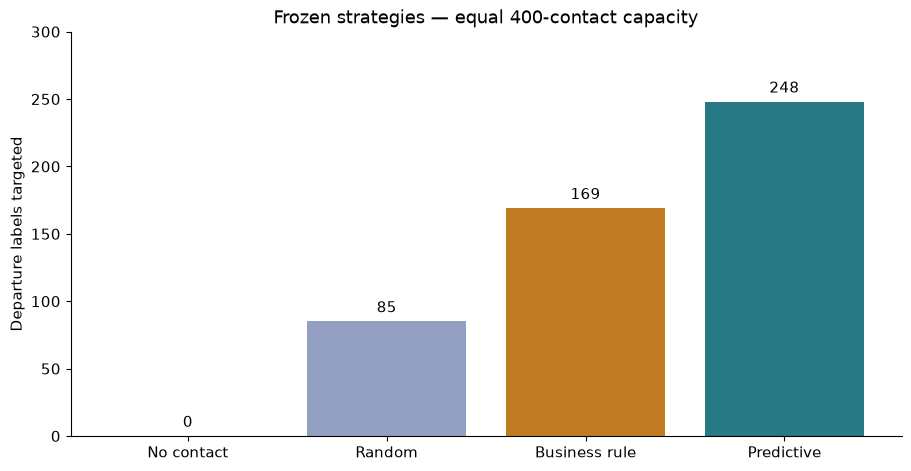

In [4]:
targeting = pd.DataFrame({
 'Strategy':strategies.strategie.map(en),
 'Contacts':strategies.contacts,
 'Departure labels targeted':strategies.departs_contactes,
 'Precision':strategies.precision,
 'Recall':strategies.rappel,
}).set_index('Strategy')
display(targeting.style.format({'Precision':'{:.1%}','Recall':'{:.1%}'},na_rep='—'))
fig,ax=plt.subplots(figsize=(9,4.6),layout='constrained')
bars=ax.bar(strategies.strategie.map(en),strategies.departs_contactes,color=['#969696','#929ec2','#c17b22','#267985'])
ax.bar_label(bars,padding=4)
ax.set(ylabel='Departure labels targeted',title='Frozen strategies — equal 400-contact capacity',ylim=(0,300))
plt.show()

Predictive targeting reaches **248 of the 407** test departure labels, against 169 for the business rule and 85 for the random draw, whose expectation under repeated draws is 81.4. Precision is 62% (95% interval 56.0%–67.2%) and lift 3.05 (2.87–3.25). At identical capacity the score concentrates retrospective risk about 1.5 times more effectively than a two-variable business rule. It does not follow that these customers respond more strongly to an offer; some of the highest-risk customers may be impossible to retain at any cost.

Turning labels into money requires the assumptions frozen in notebook 03. They are **illustrative, not estimated from campaign data**. All scenario and pilot amounts in this report are **US dollars (USD)**:

| Reference assumption | Convention |
|---|---|
| Economic horizon | 12 months; the label horizon remains unknown |
| Cost | US\$2 contact + US\$8 offer, paid for every contacted customer |
| Net margin preserved | US\$500 per prevented departure over the economic horizon, before campaign costs |
| Retention effect q | 20% of potential departures prevented among contacts |
| Capacity and cost | 400 contacts; US\$4,000 total campaign cost |

**Simulated net gain = q × preserved margin × departure labels targeted − cost per contact × contacts.**

The simulation assumes the supplied labels represent departure without a new campaign over that horizon, with equal eligibility and reachability, no effect on customers who were not leaving and no interference between customers. This temporal and counterfactual transfer is unverified. **Currency convention:** US dollars were requested after the original evaluation, and the same numeric assumptions are expressed in dollars without applying any exchange rate; the historical `_eur` field names inside the sealed aggregates are left untouched, and neither the model nor the test results are rewritten. This establishes no currency for the file's balances or salaries.

,Scenario cost (USD),Simulated net gain (USD)
Strategy,,
No contact,0,0
Random,"4,000","4,500"
Business rule,"4,000","12,900"
Predictive,"4,000","20,800"


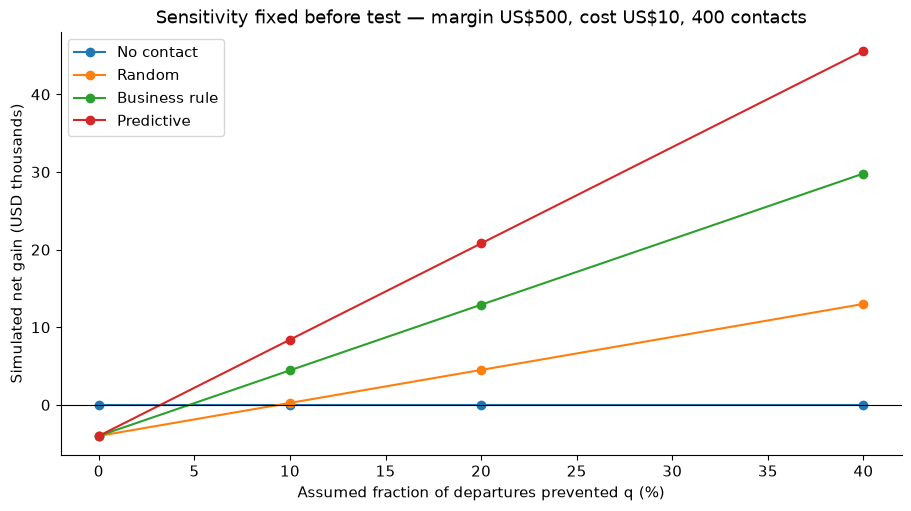

In [5]:
economics_table = pd.DataFrame({
 'Strategy':strategies.strategie.map(en),
 'Scenario cost (USD)':strategies.cout_scenario_eur,
 'Simulated net gain (USD)':strategies.gain_net_scenario_eur,
}).set_index('Strategy')
display(economics_table.style.format('{:,.0f}'))
base_sensitivity = scenarios[(scenarios.marge_eur==economics['margin_eur']) & (scenarios.cout_par_contact_eur==economics['cost_eur'])]
fig,ax=plt.subplots(figsize=(9,5),layout='constrained')
for name in protocol['strategies']:
 group=base_sensitivity[base_sensitivity.strategie.eq(name)].sort_values('q')
 ax.plot(group.q*100,group.gain_net_scenario_eur/1000,'o-',label=en(name))
ax.axhline(0,color='black',linewidth=.8)
ax.set(xlabel='Assumed fraction of departures prevented q (%)',ylabel='Simulated net gain (USD thousands)',title='Sensitivity fixed before test — margin US$500, cost US$10, 400 contacts')
ax.legend()
plt.show()

At the reference assumptions, predictive targeting produces **US\$20,800** of simulated net gain, against **US\$12,900** for the business rule and **US\$4,500** for the random draw. The left-hand end of the curves matters more than those three numbers: at **q = 0**, an offer with no retention effect, every campaign loses its full **US\$4,000** of cost while no contact stays exactly at zero. At q = 10% the random draw returns only US\$250, barely above break-even, where predictive targeting returns US\$8,400. The ordering of the policies never changes across the frozen grid; the margin of safety does.

These are algebraic scenarios, not measured gains or a validated forecast. Fixed and implementation costs, opportunity costs and effects beyond twelve months are unspecified, so this is not a complete investment case.

With a homogeneous positive effect q and margin M, equal cost c and a fixed contact count, expected gain per customer is `p × q × M − c`, so ranking by risk p also ranks expected gain. That equivalence fails as soon as response, margin, cost or reachability varies between customers, and this study estimates none of those differences. The sensitivity grid was frozen before the test; it changes neither the policy nor the quota and establishes no optimum.

## 6. What a retention team should do differently

Three changes follow from these results. They apply to targeting within a customer base resembling the supplied file; extending them to a live campaign requires the pilot in section 7.

**1. Tie the contact decision to explicit economics, and treat the 20% quota as capacity.** The margin, cost and effect assumptions belong to the retention and finance owners, not to the model. Published as conventions, they can be challenged in a committee and moved transparently: at q = 20% the predictive campaign shows US\$20,800 of simulated gain, at q = 0 it loses US\$4,000. Once those owners supply real offer costs and margins, a break-even contact threshold can be derived and frozen — this study did not freeze one and no optimal quota should be read into the sensitivity grid.

**2. Use the multivariate score where capacity is scarce.** At 400 contacts the score targets 248 departure labels against 169 for the two-variable business rule and 85 for a random draw. The gap is where combining age, activity, product count, country and balance adds value over a rule a team can apply by hand. Where capacity is large enough to contact nearly everyone eligible, that advantage shrinks and the simpler rule may suffice.

**3. Validate chronology and calibration before any deployment, then revalidate by cohort.** The missing out-of-time check is the main obstacle to using this score prospectively. Establish which features are known before decision time t0, score a dated future cohort, and compare mean predicted probability against the observed departure proportion for each cohort once its follow-up is complete. Refitting should use fully observed cohorts, not incomplete outcomes.

## 7. Limits and next steps

**Retrospective population, no campaign data.** Nobody in the file was contacted, so no response to an offer is observed. The study can rank departure risk; it cannot estimate uplift, and no retention effectiveness is measured anywhere in it.

**A conventional label, not a measured operational churn.** The departure convention is inferred from a matching public example. Horizon, decision date and censoring are unknown, so the proportions are not annual rates and the economic horizon of twelve months is a planning assumption rather than a property of the label.

**No temporal validation.** The split is a stratified random partition of undated unique customers. Performance is measured under an exchangeability assumption; there is no later cohort, and feature chronology is unverified.

**Assumed economics.** The US\$500 margin, US\$10 cost per contact and 20% retention effect are flat conventions. The bootstrap intervals cover sampling in this test set conditional on the frozen policy; they carry no uncertainty about margin, cost, effect size or market conditions.

**Thin segments and one-way views.** The four-product group holds 39 training customers and the three-product group 172, so neither supports a stable estimate; the frozen aggregates offer no adjusted or two-way breakdown, which leaves the age and balance reversals of section 3 unexplained.

The next steps follow directly: confirm the file's provenance, licence and publication rights; obtain the operational departure definition and its horizon from the business owners; establish the features known before decision time t0 and validate the frozen score on a dated future cohort; have retention and finance supply a real offer, contact capacity, payment rules, costs and net contribution measures; and only then run a randomized pilot, registered **before randomization and outcome observation**, as notebook 04 proposes:

| Element | Proposed design |
|---|---|
| Eligible population | Open accounts at t0, complete follow-up, no concurrent campaign; initially the top 20% score group after temporal validation |
| Assignment | Customer-level 1:1 randomization to a prespecified uniform contact and offer versus usual-service control; stratify by country and score band |
| Primary outcome | Difference in 12-month net contribution per assigned customer, treatment minus control, by intention to treat; include actual campaign and service costs and realized margin |
| Success | Lower bound of a two-sided 95% confidence interval for the net effect above US\$0; 5% test level |
| Size and monitoring | Plan 80% power for a proposed US\$10 economically relevant effect; obtain contribution variance before fixing the sample size. Prespecify missingness, censoring, incident thresholds and analysis after complete follow-up; no opportunistic stopping on significance |

The twelve-month horizon and the US\$10 design effect are proposals, not measured quantities. Unreachable customers and offer non-acceptors stay in the intention-to-treat analysis. Secondary outcomes include departure, offer uptake, complaints and opt-outs. A pilot restricted to the top-score group identifies the effect **in that group**; proving the best policy for the whole base would require broader randomized exploration or a randomized policy comparison.

**Decision:** prepare this measurable pilot after validating the data and the operating assumptions. Keep the score as a targeting candidate, without treating risk as uplift or simulated dollars as realized value.

## Evidence and reproducibility

This publication notebook summarizes existing outputs and modifies none of them. It can run in a fresh kernel after the four analytical stages.

| Analytical source | Evidence summarized |
|---|---|
| `01-data-cleaning.ipynb` | Audit, documented label convention, exclusions and frozen split; `contract.json` |
| `02-data-analysis.ipynb` | Training patterns and Wilson intervals; `segments_train.csv`, `eda_summary.json` |
| `03-prediction.ipynb` | Validation choices, cached final evaluation, policies and assumptions; `validation_metrics.csv`, `frozen_protocol.json`, `test_evaluation.json` |
| `04-business-insights.ipynb` | Business interpretation, frozen-grid scenarios and pilot; `business_scenarios.csv` |

Execute this report with `.venv/bin/python src/run_study.py summary`; export the single HTML report with `.venv/bin/python src/export_html.py`. The independent review and the publication checks are recorded in `reports/review.md` and `reports/publication.md`.